# Predicting student results with linear and logistic regression

**Main question:** How can the same input features answer two different questions?

| Task | Target | Model |
|---|---|---|
| What final grade will a student receive? | Grade from 0 to 20 | Simple and multiple linear regression |
| Will a student pass? | Fail / Pass | Binary logistic regression |
| Which grade band will a student receive? | Four teaching-defined bands | Multinomial logistic regression (extension) |



## 1. Dataset and prediction scenario

We use the **Portuguese-language subject** file, `student-por.csv`, from the UCI Student Performance dataset: 649 student records from two Portuguese secondary schools. These are observed records collected from school reports and questionnaires, not generated data. We use only one subject file so overlapping students across the two subject files do not enter different splits.

**Scenario:** predict the final grade after the second-period grade is known. `G1` and `G2` are earlier grades; `G3` is the final grade. Their availability makes this a late-stage prediction exercise. For an early-intervention scenario, remove `G1` and `G2` and evaluate again with a new development protocol.

We define **Pass = G3 ≥ 10**, **Fail = G3 < 10** for this exercise. The class label is derived from the real observed grade. We must never use `G3`, the pass label, or a grade band as an input feature.


In [ ]:
import io
import base64
import gzip
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score, classification_report, ConfusionMatrixDisplay)

SEED = 42
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


In [ ]:
#@title Load the embedded UCI dataset (expand to inspect the loading code)
# This is the original CSV compressed as text so the notebook is self-contained.
DATA_GZIP_BASE64 = "H4sIAAAAAAACA81d264dN3J9z2ecL2iyyO7e2E8CEvklBxiczCCPwRn72FZgSQNdBpl8ffbubt6rilXsrSQQRhY0tkWzyWLVqrVWff3598+f/7h+ffuv6+tvb9fXX3758vb16/XX149fP/z32/VPX7+9fvv+9fr89sv36/v7T8//+fmv1/f3n768vX79/On62/fXL798eP10/fbl9e9vf3z78PHt+vXb91/+sf3q19cPf3y//SuvX7c/6Ov3v23/7ttf/vb64Zfr68/fPvz9w7cPt7/h0/cvX9++/OP6+4fffn/7cv3w6dvbl09v365fPn98/fTtw8/3f+7L2x/XX7+8vW3/6t8+f/7+7frPr3/8fP33+0+/v73+8e336+tfv759+vn2L/zJXH+y15/gn55++tPT9en909Ws16e/3H7505/h9vO7p6u7/Xh6/fYfv3/++Hb7nW9vrz/f/uzbr37+fF/N7RcfP3/bfsfefkzXp3+8fb395qfPxU/7b1b/l7vC7X/m9uP+16fp9tvG3JZgsuUs+XL+/LT93dlyjj86LebX1/13zL6Y7A/vrMjfFgHHYuz16YItxu+L+dd/4RcT/ho2xgg3Jv0NbluE3ZY03xZi76u5/aHGtquJW+Pu696/8O03bgfl7x9+3v6Nx/LScgDbmnYl2c/7cu7/vf7+zxr3tP9kXLaguVrQffXNphyLkXwn8tDY7R/bV2LC1oRD/JxWEj/U/R/KdyQs5svb377fbu+Hz5/azyXdn/3wuLio+L1sZ1H3HaW2B1uL8OS4eKemfWfKlTSXKtzxsIJ0w6u1FPdb+K3MsZj7f8eTmbBvVVyqd/tRw74VszPcYvKtCWfYbFvj76uZ79vRriY7w071kcQHxh8r2U+xxT5Te8Fd8XnCVdecYmZ/4IiAdj+Z+B2v13Tf0O7NCpcddJFn36jw0dy2URN2s3xz3R0eCZFnwmhX5I5tgvzT5bH5Gf10kH+65tmq7pjiq/nt3222x2KiQo+vLjwXevhXgtset32tFHviAfLMI1F+K/KGGfVl3+Pg/b/0HpGXp/2neNnJtWTHJfslccfU5xm2D7Wvy8QADSMvKbokIII0vpqY+YQrZsOK8nv/jORhdZTGLln+9UCSZVQB8n6a9jP1tD5t/1t6bzx1kLD73j3Pxwcz8boXT/vAde8GavETb7J3zNYn6Jl6O+LuNNtEx8PuGQq5j8kTsnqD2o9lRfEQ3xw+PPvjwHl6d0SpGPq17Fhy6NJR3p+w209mKt/Vl/JdLUNR/GLIFoHwxtf1xf7N4pJMtaS5eerJK68I1+jROuJhvGRxPdwlk+XPZjBLvKfyK3WcxaVXWwoa3WW320mw25WPtyuvS5vj/O5IWsUptCQkY3XyfnS4UofKXMkSo01aBT+77WbtP1xYkel+MScsli0dEAkgwW1vvDsC0IR9MX8y8xgIQ+74bOHDbeWPz7KzZyQMVQ9ZwjrYSC1FFVLC6FOx6tolFbEazYVUDweJ/9ijUi0KZ8ucazgZgsgDFG6YwzIOvA5DdqV+3a202omLg6xOdVT48Vgmlg7Nw5CocnMcDkQdn+lFgG8QN0uPjtnqi0GNc2AvPPyvvvCGOEQvzYva4plE2mq0hUaKQHZ7Wh2Gao6gZGw0xFeVwA7Y/sx0sqcesNCmrXXlrLjw28/++FzuyDmGngwEme+ArBKUowB8PR6aJRkihbz039Ty7meFzwXLo9njgzxfKTRuSJYQ6ci2yG6ZonHYZ3uPwJtO83zJU7PjHCWUnlxQmyxmC9IkQv3UdX893NHEAFmmCHheRgQhpy4PbXzmLYYLkek9ee21O1TEw3CAXB6juyAweu3bWp6DgtBl5d0DiyVB5BUTQkEwgNrDAZplDz7gm1TCCw3IQfTl1ItJUXEO2cfMNDTKxZDQi5WVhhls57ek1WWX/RYSL4qz0wPtlPEZttXYCL0Ak7ji4Yf+Usqyed8YF8tmtA02N6i4kSxFg0gdYTn0uW0qmdlu7ru2ZdkPhUNvfNMQc503/hFNKLbgSE/YmlepM5OWGfyRx1vNw2l0EX0c20bAO5iCmrm7Se7oH4S8fq73531d/zRgR/tijH8ue2CbITovoac6M/tjqp4hlyY6tsyg0un0Y8oB15l5xYozRF029ChJE49U/hR9n4k9SYBeNryOVp1siKi06l2VBaXBfYpwnjtQz0mag9CQgzQFkYAO9uAxzExQwkEHTSIrPOVmezr3HGCiKvwWsDLS0OS0z7+LJXW6dhe8zVHmjuJ0X8xAyRcV2ncu7dLU1mgvJcRoOu2glLQ5HbjnjgokMLtQFBb9aqfXIwOKQIY9WFER63RZG2QcvPCxLp1GmenuDVNT91YVMlrHbY7+a/FpbbdVb+MV05MHugW+Oj0KwFUPHu41x8+TqlKp6OleWbuaScjMcWrmQPniWwaN4ZuaCuyDW5U/csf9kiEwNUb0QIuiBn/dCB7s0ak+pIuNBQhY3qWTDEHJRFZk1X2kKnGojMM+1XOv5TICdfL4dOiIQ3mWrXRF5L0CkozMNsZsxhXAcYbs/bSn6bYijmvV8OWaUnL2gq0rfHlTHHIKVQ/JM8zNEiH3RIIRqOOOhvBG2885Wq6LPS4WikSTnkQWH3jjG+VBYAcCg9zzSc+jeIHpBJltf0R5oZXcM/6bdcDgQOeMzLepQz35IRzlglAeqp5Z+mqIY6KO61rc+IvsAKlUCGaA+eaPIzRTFf3chGpxEFIQ/yFmYhbnSJOwmYQ2MMTBg6z5THBce09G7zC7kYTVZcxbUZOeEB01e+T03K6AcZgjCAGhrXkZPtW2TYW6WWOqCl249II02ihJQt1zHa+9rxlLtnuw3QMKQjI5c8dXc/lFgx6qyPTEe7Bip+/iswaiZdRZkuyDaAQpi9TEDjQ2vhqrYkVckxUGaG8lh2muQXMJ3YM51IbhUHa0j17YoPqzWKc1hNmFQ2Qzbs6Ec3Mi3gryDRqkcKdSfsbaHO2CsmuGvx3pFDm9dDYcITMxpPI+uPAI6NfHhwMS8aT+YGhmRh+gwRtWn2fHvPYv3ShdrcXp3viI04ewuGJpNN7PYOUaZ6S8PmIvruQBO5bDQBC42fAjy1v3Fsa+IPRrYS1NkGQd1RFSvhomEoVQaJNE77q5mdFzzVJm5rc3bGUi4oDIxmhx+iT026LPGlhUK3PBtv9oBbVrgGfhGvrbpROE+gf7BInSRxHiLmuZmaoDj0MEWRmr6aUc3JB77McabWUqOwg8g0mimzfHBjmMgbI0BRDHoExa4+28abXGu2TdK2Bg6Gb3vPiQvWcBl3ZJkQ0dRbYpYxDP8SJhPKISszESkeR7r5aNVVmQVkef3zAR5mHzL9bS7tWXq0jtbQGWO7E6qnnjBYm9kORhYn9OVB4+3JciBmdXOx6I7pbw7Bilx0rgTx6f6tJpa7xTeUGoGC++4uGhtO1LtTVTxwgnW4/lCArlT1CKeS8E5Puie0LHc0M4ZOD307NSD8QsaYMhDV1QyjQComlzeMwqZT5MhmFHYGhbEAImrK2yjnh25Aca+kAUVmFsNU/GBFpbC5p4t2SAHajlvIDJeacOUN8zmeoshwvOiSS1gZk453+RaKCkXibc8QnvA+T8FhbOlAAtJ/Kd4EOxVzl7bUqI98vjLPhaTkmwT0F5SxhCs8mwDHKZHtSoeP4QH07DMbReGLIEE5SdGgRH4cJ+86s8NX3cWZl4EZAPV0lIGSUgy3ayT+Zy8xKUCTnL2jrnPlfA5qB25akh+RVrCwqVIrqyL+PVuaP+Q9gtmBMhEAztNuWBsajs9zvGcbVo6mGfu6rRXlca1Qw5NJ0QxMvjJYuhtygDVy40tlLaI0oReSu8XxmbJJm8iNBveZ5qB3rvUAAZQHin9amraJJhtEBY8pc7wMKstBFwMjk2m9W3B2wU9QDZwUW7J0K3GQmKkX5pIkPq9k8eR3ktt2c+JZw7Qf7xSYgFEvtIFWdLDR/YKFC1ONFOcM0evFUu04dZymph5n1a2dRjAKILuYejpPsjnFq9c1EouzZA40A0lqfrLKUg8hTWEZJm7tNqJWJQK+S2dE9y/RsOMynrPRjQMdTNN8eorTZtRpMwkotlHsCGZCij1ePVZ692YWbs8EgCtI2qC3OdO55XJ1Eo/HPVuwQRRvDbH4wwSNCTLMl9nDbiuAiJMUDqikVAQeff8HlYvSx7IAc+U1fdNmZiny0jPMWytKdOCgtyaNdmD4SCRhIzFPmT2QNFA/zJekbg3Zpd06iax0+zi0YqCYK6dGzXiabkuGtA/tkS5XCitqftJYOyySXMLyqBwfZfs+wJ4toiCbh6uEvxAwWWYKNccG9KHtlqcarXQSwBGmNW5pehQ+qPEnDG0FSsPyBl8QMdCbG1pFYbpOR06mrzQJ7wGL39sT9gjaIoZUtk23GqzpMeq+jV7uuA8EzUxwY7xNLQbOvQ3KcZQiZcXKOd74XF5qyoibOdLmkxWoAHO/t6u90z85hTt3sYNajCTOFx3KOrmH7cy9F3I3zM8yJ0v1fhwPBBr1M9YJhlJ9wlhHmPM9vhXdG1DPtR227YK39KNpW7Z/e6F1ZrT5kj6Nh0cOVGNAkHruzQ7iypqhAWMVpJly2A5aUmgT2CXCB0zDSR0khOU5hljtgP0ChWFSeUlOGFfZ6ciNpkaGoTQdwJDQnbAW+zSDP9GEvsCk3OdqcmEC4y98XH2SGVoLIRqMvoeCwCKXuAu+f6NricC36ckbnLmMMTw9bjnFlEky/kjjrhx9RxO9RJJiVrIu9Z4FsV8iB+lAKICYRqCScc63GRxIxc/BeZDI9zZdP1aXdi45q1Rjm41Kkdn1WOmYCxvLselQMGFhIBnjtYRpCWI6ppdAOTxFZMtpgtY7rDpJDJBUKPKAWH2UcPHZ8Sj7Wa7bIMR8YRJ3MfBa+3cG2lRnGgQA20+LuJ5bFJzLma6L10jhJ7+cde/eAWN+ez2xybiFilOlA52Q6KM44FJBTDPGVB371wlSH+zExvA3TwjfoY8T7ZEKQe6DyVlqIv1cHoCFk7k8WnNvKlO7MEFI1b9SAeiI/HTJUdnQGW+gXJhG9Q9gYsc+npTk51xIccJMJ0DkPOdZkHMfkTvHgXLYWJdqCYViySwHQE04DNa7QsH9QpfNYHohAUHqyip4OWTDMNC+EWpaDoMNOz7BCVzz2Zo+WVtFpSAUdpBsSZfn9mdyxe23ccYd3BTIcJ+1ykwBRrlz7Mo8lHdJ70XeTN3x9rDOcPyoiVDia02oRRNwrDRfsYRzl/LBLDqNH2f9PsglzU5avNWbCejtrSQu4hEY6ONQzH50UoMyNqe6d01vKZ98dMLWvhTev4WThG7gWdGUlAFCyurc6ipYeaUy4JnXkPEAeWEaReYS39ANd1kxH4HXWuZ5nyQ0ZA6g+tdrXBBjB3TDNE0g7akOSjddEYdFGDVefskKDu6Fo8ey0fskePi86aUHsX9d4SlKljrLam109Y6HAlViHk+Yh3NTUwadp83TakvpiwmueUDqFLlxnWGZzZUnpVqhFz1Sx2OEzHXGgBeTZTHMGpZIExtYFMMtap8eAVA84wFzSZVWVH7hUs6GkTmwXLy8gQ3WE79yzrIiuADNGc38fjNE21x8/EwAsvjBjuh8yRtJFmTGb2i+xdPeeeWdqyFRo5K/Flq8Gh7mAMhbrcRrtBwJ26yUgtmHUHupkhED0z3fVCy9GELH7NDMfOpE2frE5rM621AYXMqbAoQO+jA1FFN3lP0U1+zBDS4HFqsc7GM4oGwSMaLrwDNGRe1JOEcWx1ekaxN1OGULnjKOFEmEUy3Yl1BRCLGcsumcfwl0U0rV7d9RUuyRGZ9IueszT0YvjC38JKfOeHACrtKQqGuZbOpmVmLec6my2Y5+opQa6nsxwbkdpRNmVKq0srIkTbmcJHfuCepTBkcUXRs9Q6QUR947k57lBgONoPcj6p+pKy8Hyty6WGomajicygw4/oA9l6WBq0qu5MKCO07bRqlZXLeitmpeqLlTed7zXojHLSbxrCHpREK74gHnLpk7K7XFITE9SAHd7SjUWaniK1DqLcYei1DY558BVmSnDxWLkX27YMOMIO9E4lW12fD2pf8orpknxV0cbFckLtCsPMTRuKdtONOGIGfTf6IZR1n3UGOfhJUCELfT/YcYjpUlmmRfCSR0DDkn4zmaBRtlF8qokdKlpkL7imjJB9LB8J7PfzUbHocVMonZ1Ob6hN7XG/EixfVOggEsbAgG9EUP47bAQrti1yX1e9O2iyYCqW43oM3759odUnFPZI0F09DNZTqpR3JEucXY8cfc9HUaMJ6DzIfx6w/neRH75IrfEGJkBr5yDZLCBTveRxwwjVwNwi5Qq9N0NwovrWLA3EDGL31MqjqhpC4tnMAmQ2+8PegdGmzzD9ErW2lINM0aOdxx5DzQ9dVXM+hp0ekwA4Zz32iNh6D0MlzdBtFx3FS5cf7eyBzM7yNEd9UVlynmDP2ZirBxywctu9O6GwI3A7fGLoOKa2xpeH95KNdYwvU64XkpauC32KGVW+0FpwJMcJS7m4zqxMixx4Ib5kGhgmGQXpFHWrrBpc5s63xo+09BQWHWDrc2E7LhwyW6LrUZu3BeGJTdRVZ9jKznDoyfqIbYXNmVl5vzkpjsbOdHDICZ0QV4+keaZKuzNVJjuy2dVORsAkxaYYdiBCbZQyRVtZNE8syPZA5mAj6Ej+sVbiZksLzB43V83GF9PmaejCMJvkA0JH2LDJnbQgOnQ7aJIAmI86IGmeTQB05dTmqQObSEd+w+gQPMjzc1spp1g/I8YbB9RU2EZ+hyzl5WlM0S6f7wTxBHtal3hpcAEgPIMeRuqGCHA5Sr+1DrU99EoXe0TB/YqjM9TYDifzZtrOC1H+lJJQRwbkRW7eiGToTt//dbHOtIRGwU6q15NETfrmLyZ2o23MQxtyzioclnqKdXZsjjlSC1sOwPLMKZbDOMPme5A+FfI0vIzQT0CVc3lsKT1li3a+riz5K99vj6UVK8/FG2Qsde3FCSX0M8UOPCsYQ97uIKHFjZTWCg8F8fTRYTIgRKtGT4RhtgJ/IOnfH294UWmazguu8RUZsamAWECslAZyZV17HskyaSZ0uDwi84mOOXeQWE/C0MmDON+uxv4uuqlkZ+Vih+XeTCkjVg7i6jfP3EAMSnQlQ7JO1geTg+g8mWlzCjThTNJuRf363CffR4txi5kJvX9AWqoA1X1tu9DD+G0pEuO9qOw4EGioKC1JUXuNtAEPvr33MFN87SIAMQMgmNMsAXkSE8bvOh9LqyL0/Gg7MPPKRn9CcfSRuJlV3pY6sqSNLRGHT7Z738uAejERxlpYkDXzAes3XrDkWcmXNvz5bkDUoBIHyntz5dvEj5u3kuNhNh8wN3VOOO/hoamUa38sTPFjKCw10BUlLVCjdzrwyYGzaA5PzHqABDDPWh24mL4ejEUgKJQSeope9kyq6vKqcJG8roqsQzMG2WdBaFKJtB4LftfjFkrNkdOmHQ+oNOI7H18yzqyn/620lC8S2wjD7ibmlZdp6oTDzwUw/LG1+9jqtTrK6PagKjGNek1IU1ZIxYzSJAcGHg2X0e0dA5P158Q/yqTTZ/OrC9PZpVdNDxj2ydmwgVwk4maUhDnNl5M7wuTeKwtxzF+4iW8jrwhv3ZX7vW43755jX1huhMqrE0bOkq39TD3uZ1qiDn2PGjMwLicfAeWITFarRRqH9mw067NlBx4YtMExaPCZ+jU8tba0xXO9BoLwWXMnQ/bMRKG+5dKpw3N0WFxEQIqHbWFIAfjpEbqY9qoyJ7xX5e60E0bO+qu52AXzbMb4ImTJPi72QD4OfSHJ8HwDXrMc7XnuPWPleKwe5KB3W7LF/LAmV3tOpT0lOuaraNCOVczTa2I4+r2p2g4t5VA0lqbFlmW+oJSgl+yCWSueE3jwNgy+EABOGLGkLRW5iy8yyyFQ4cSTstLFiDk3diR1TeNci3rR99xOVKJshdWsqUfQ1dXrwnfKhKo7jZ17muzo64EJ4kf+YTq3fDkoh2xlpTBSEE/jlrOx49M0YNvx6aPt5xCaCah1khB10AWRYumpWRn9wJmJkyaS9lfsRD+jKbTVipc0TdbQW7hQQslOX+GB9nwu2gVWcwOB/VpOyagd2R3HxB9Jl+MB0cdnqgbyui+Njn7MXVpsQJdSIFPI8RZGHagbB6Bxn/MVi1XE9rUCJZUZIFXYOFHMUnd95UqMTkVoBjAXHw3WIn/BMNW7kfDtoIvbVb9rMqGtIfOemjoqXEsa0y63O8iahmsrpF8HwfqxySM+TVuTms2d7R3QQy8bYT8rFBeSRk8QsdOMPii5UxNbBBoFkRV0LZY0DkUx6GPq8EwE8s2e/Nfi44/GG2F6bN4XgJjDdNorN8N1iDTKgQfp3ER0DqRDjzQO/+K5R9nwS9JH7UXik8qObJbnXv4IzJZKBU/poofAb3fEn4ka+j3uujKiuU3Nwp4VgriaoB+MvpjdZVI421Et8n5TyHLcwHJ8fL8mSseOcl04UrQAc0ZPlY+sVmKChqC12/MEVCFP9jBDSIIHwtWDYt0xlSiMNCzyTFkkMRjz1Jf04X2cQe4T/6/3cjFjWB6g3kl54UopDVaFldupKYt5PzkcHNtTfInsYNzIQOA0mR0dIoZOGJA5+oOejeQz/biRLcf+GF5tSDFs2cfxzInRHGE3MKUC6vECjoPj3v2IzckTsCYxnc8QWE+5WKZaglRMtx/L/bAxhskHYcZG8eJ2sbIyYkiAlkZOmpWRX0h8z6W5oIgWVYmbHPs8yLSUqqgTkcGgAHO5bf7CKOIU/NmRFSXPOxSHO6cYBD0w6I6pWJXRphOzjh7jwI6kPFBPE+GpmT+m3VZMm9xwlhiGfLfhpuBBDYuLbBzJa7FW+6XxbwAZF1vjAGqj0r2ezmd6gI9AeW8GphkljlhcToWJ3edBKTHd7ExbnZsZZEb1U+YuZHv1n4qX2VM7oQLQYyCnyfxiLEPLBPkuDb2u/kB4L1JXs4duU89XIgM4Fs5L/52IUXfmnXXxGbFUPFp5t5TzZo8tT7SYMF/t0P3Cqbwws4Bt+0Bdax+9x0ZrcCOFxrSgT17/PAD3RhP9YEEUyx8RJZOkGgs8S5nF+IgjotwjXKfyg8ZL5y5ESYy6dmQhEof4U7BLaOLel4UfaKSaV3GijLZpYI4n9rYwwLirz6gXkTkPBfHQS5BgLdijv2JGvHIm9ihzA4IsrPlw72tq3Xb1JzEh0iQFnzzlD1w/v3cuu/AmPGDQGjWF28Rh7q5KjZ7/jfTcRpPG8Ff5pCxMrB/q6XsKUiSO+XJe9K1UOzqFDqEl2Gw1Hns32KHXH5XBOgejTTEXPO80kwuSdjLswDzVpLV2FSGA+VogZ9Lqxrin0cC+Ic/X29MbJySSgJJdDZMZJd3+sTnSE7ZlNGOlQ36oGmwvnFwI0ZLIYxfqGZniYWRWnaCcXFb3LtDLvfB9JpbVZ4RnJVPoIpTiiVkNmhTWcU9rHO+jEaQPh2XebEPJKy13ItcOfTERl/eNIKZ+D8pHfEAmzN+hZPGVO8NNif9EXmkjG1XYGTzVCXy5/JSLw7hfSo/Ba8bagrsZ0HaEdtEHGYZFdrxWyoZqDLYKgN5UT+bCJcoPfZ+Cr01rO8Y/lxJ/a6t2ezXF1E2X4XN4KGaPssxph2tt+yMG+j2S3/P12w5N2WqWAc5RA/T03imXDd1Lo8bzt9I3c36NQOZ6os3ks3KvVrv//1jVsn+vS7rkmINygc414BM/jIb8gJDZE7gSMKj3RshIxdgZqjO8g95r3JPq8LStW6z99sjPlKc5Bku5RAbT7YcyOsqujz8gePrdP9WFeRfGiFgKaZDNaAh5v5QpqKz83dSUCz5LLiBnIUCvfJGsBgbACh9bFbV9KHnFjXq2pqySgn6qPlaHwxAi6NPsoAtRZf5l6NCYTK0pqqhM1rKd0gy39f98MRD9oNbyNv2FGVI2ouFgvOwhfN4LHmpUA1+UY4XLRyHsy1Q1juoInKXnVjPfXCkUSOmoP95x4aWSzAtyDMeoYw2cDYOdOpGP+Fx19etyXEA49yXhAhXFUoqykR64gwwjE/CEwsJ+dGtO+YjZ43Lbkkzt5JuDzGlMznjqGT1pKg6JD3hMXtJHTcbOjS2VdXl59zx+iqWfqsiKgz/wjGV97yknPNFwT6OkqEAGzV6ah+EZeRiAgCcYIFRo0GML+g4G4MxCO33p+ZUxhPcL7ojarmUVyLr3oMxCc3WCqeQSJCxAeJpIn06e8A4xJ56w9ZCgyUluU28Wda7pBawTMw+zqW1nrDDKprblcBqDr0Y1LxxUeFsz3K6m6NbHZ8zNxOj9nVycZulShmwmBjwxgkFY6l2qLefgaIcQqZcXesxKJUmsx0r51RqACT9BujHvCs5nnX513woQazPtwJRsOADBnYhWzEjU5mBoKQyqPAOymFg4KuWAtmqeuaKIKJ8Ql3nzpMnLRaZ84dnd2KdC+tEioUvqj8ea79JpoFnhkE/Q7EzEujLreBQl8MPjl0VMhnwxSYNNV8MK9ESesCPGyAnoYsET9XRs6ZaUwz03p3j8Eg0/33pZgs8gHCNBlMQ5KcVQZiOeO0QJcK34iXnt8NLl4GEDam23FZ1bW0Es8OYIp7PxxchzCdN1RmuuUcpFZxTdXxVwyUeWzk58pPR5IOAsK7Irq7oE/9gn16OLSyOMmqme/DeSDOAyWndIk8x20lhaMsy9oyoplnQseZCgnDC1EmSOaiKtYV9pCRaA7ZY9DoxPjNr6uMw8+Kjcls7RDS3wqWmuvqdG0p5giHLBLpVxrpQXAbs3Rqy1NEPqogCy2crwguyDAzkPEZXqGrEwJPN/T6OmJuyKsyPCB+yiZB1N06jC+PdSph6WOii0qnyb23DUXIplEG3rDs7F9AX5dO6DfrMwFbgTuS+aoYEc/uAWr9UwFbL1wWhm2ha003eofFV5r4K+UO+1OkKIeNRM0KWZ2tm0Bq8vCnOAc1JUn10pi0XCRVbiksx0JRfcZcSOiYCwG648kOVl2/2wWl9cOISWLhPKXPBXXU6z08pASqytmdVoKmRrGeyKdzijVFM8p69e0NRLXO0ON4V81U7Mx6Tx5d1jp0eSC/IYEXxpWM+ThBFplTc9Zy8Y4gyvY/1Eo8/YXaY8vcQyfGHzQaP0zZMOIzPxf0dmOvM0iloFIwTWFGoqc+zPti8VB1s4KJw7wfIp3TZKX7fAd6kQdJK4FQsrYj6KxBeTs7OprEDyjIssa8RCKq3Tj4vq4No0D2+4vjucmTQ25UYFLNmotjCBb+d5hiaVtj9oRKyPYdCGS7Ykiu97JDEVhh4YAt1s8kqZUdqUUCnERWWFJyWUO9MABvOwSbAdF5hCIEFXPRjUcxYZ7SnzH+LLmfTDbif4/rW4ew64eElzaPA+q82HzSOEZ3bWh3pQt0C7ZHPfNVeFv9bU3kh0VEadUdi4FoNxcPCWr7jGc7JqpuDR5jadk6gPZGUZjtEMiUmrMYe9YkDfLkzIY4ay6CWt6N6kb0WRwYcN8gZa4ebQ+kNgzOetKVL2IQrEoE6PAzgJyARRkv5iKamFIl2n0hybj127oEIq2oacVfvaQZuIwkXDd6gdFX+/QdrPGJEH/wNf+jBZVvhhT9HlO3NqfCYWv2DVuJe0Ngkel36eaTLPWqm43C7IKKy3zZCD8hF+TI4zqalKKnsxdNeSeV9me2u4XjT1ho5q39L/GbxyjmnqF0m/CNi5xSMqlGpbTDRg6amirUy9WVedPSaFjxLFdMUvnb64wkzajhjShUJ4fz8njOO7sKUwg3NtrDMtIBkMKmxMLlZWViAbs2SUvsT+KBZIDuKzwtFVCCxxd8tn/Oc1Nho5klSvmhqf1+OjZ3MmYkcezhcy0LS3fNinJzybuQ8wdr8rLNJIRxXbkdHk4fRYiv3SXimFx4pKNgT4IIaVynHeKag4VjN6O7MKxKc6MtdKoG+wunmX+dGxuUzHVYsRcT2wYyM3Uas5MLYlNWAuYSigPjbIvrTAsYkBWZjVSxtnQq6HEC6BAyg5NHhku74v22wMgEFxm6rZcrDZvaAnhkVpz4PqDU3eEUJx3O7FCOMMjLxPkeW84Od3yFdqSJQdLVbWEGEmltY2dQ5w2UdUqagQKjrBGMCDzLB8gDrDPkJKGJz0TDVjhHQ7bZ0Zaqig7JoEfC4FWdSqE7+CjZ5U61ziJx9+ZVSLMXEcvCcsRGbMz4mjBZ0YyOxj+W2RRuvzQEt8vD1VD1WZEJwNbfsKRvr2DYJwB1Sb1y0LvxbQ0Ld05tCQz8127ZG58HV3L9yATraZHCAO46T7wbm0sYZivLAP5kiWFRDRy745a6+BKB/dZgenacJBaZ0jw3dlPpeV+vjSnwr9dMkHHvMJeo/42CkIAwJX4fq3bWD87RCS35u9C1Pxmg7hWI3qN4+4TbSOKvTJ/I3PRxqXnRcTmNiG47uox52O2VTuTLIVS9DJ+HfKkwy96zbrra6EedJFmGyVFwxkBojttkC2LRdJZ0o21NgMeN+EsQGNxALP+UAuPJG4d6JsF8D0W92vhLtzg8rYrx6t7EjlSWveKZRNWZ31A+Q6UYTAgc5+HZqh13NXLXx5j5UsDKHOSt0OVfrHyPlO4oq5ZNcsjevi9IO8eDXmqpmGjH+QSNyeGShRDlGG4HG99MBgyw+N6jkT9Y13TKhSDnINKa5TD8RV2XOEHBiSbdPSch/b/ck73vrcgfl2qc3scybUheVYS0151R7yPjefWAghpEIu8BEZMS2rbSGz5YWY+S7MSiyZb3Z9ZxXDZwMjinANWAa0+o8IO+1wJpw6Sz9RCs6jiKnFWCus0vGzah4m++ECkL9iXY61Q0sSa/EUc3pDlwxC64UlyWv7QEOT4hzeBzozLhOEyhNM6RH1+xVIsfIhccxACSdBmgiJrpSD+4p1wIWMLd384qb09ZQ/rhQzrhtl0PFVxlINKKee9a67PX2K8f0yEZm1GYsXe71UmcbQYPlCZubqAYzAOAsQg6G6Xk7C/nM+AGXacZOpycZGLQa6VXB9esLgLFuYhowZHmBsUcVifASwLbExnayZwdLdEMcYYjmxYvG4LidUEw7t2MmBbAoT2vtd+SJUKo0WNaN9RLNL14Gu55+wF22VFitpUMJEbc+lgt76nTNJzxVdHhxqf5cUXhNadnU1480TCgPHOWyNx8RCOI0MZKuxGr+XpsdJWsGuJ1y3VINi4uVyNYDQm4dCk/+k9Bcpe9VS85fQ2XTnghCzSybTXkzVwHu+O00DuCMDJQrTk8DkckzuIxiOci7fwGztLpgQuE43jCKLVxNrQ/YcZcmeUwjyl0yoOpPIb+GYRIuaay680qvTcNQ2+Gw2qsphJxonVA0w8ESzJWw80ZHxVtPv2rY5DBqF9d6x3H8AgcbIqp2NiOdesZyc6DENrrTsIs1rjZahbaObbgJXL2z1BfIINGBnafuzmdB6ufXTbUtTbUUI0VooEmR8AyQIfei5QlnIVcz7WiCUPRBmliILlB6+Gtw0Vmo606Iad3HGjcBH9YNDjczWhi/uxNp29TPq8umBuH3FiPOd067EZfMlHPWNLkon1nG/udyARfGVZOoUM6Cud/GJMJQZ/irxV+vN0BLsjImzXE0+WWfukW2FOLxutmzZ0jfb7N0VdW+UwfANM1oJwMPhw+aOeivCyxwFTjSTSWgOSPCYkp3wxLI3QVY/WDVJ0eX3CVeYXpQ4rridTnCYIOGCK/pU8s0IpKgywlOSXWoXqB9La5mxjmnZrVpWD8XghDi62rOIIGAJzCkbo4BNVgNtLy1cwWEDHYscGPRuDIJSR7rVtp4iMlor7VWLfjMfoWRfPpUc+r/9GfrnSd5Tayo7X70JY910q6Gt75QdE0H/OWtEXBgzD1BIo7XDOG302CQmaWOpuZgTDerRoGFIva/hwP8Bgvf3HyRsAQA="
df = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(DATA_GZIP_BASE64))), sep=';')
assert df.shape == (649, 33)
print('Rows and columns:', df.shape)
display(df.head())

Rows and columns: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## 2. Inspect the data and define the features

| Column | Meaning | How we use it |
|---|---|---|
| `G1`, `G2` | First- and second-period grades, 0–20 | Numeric inputs |
| `failures` | Encoded previous class failures | Numeric input; an explicit simplifying assumption |
| `studytime` | Weekly study-time category: 1 (<2 h), 2 (2–5 h), 3 (5–10 h), 4 (>10 h) | Categorical input, **not exact hours** |
| `school`, `internet` | School identifier; home internet access | Categorical inputs |
| `G3` | Final grade, 0–20 | Regression target; used to derive classification targets |

The small feature set is chosen in advance for readability. It is not a claim that these are the best features. One-hot encoding avoids assuming equal distances between study-time categories.

Check structure and data quality before splitting. Keep predictive plots and model decisions on training/validation data. A duplicate record should be investigated; it should not be removed automatically merely because two students share values.

In [ ]:
numeric_features = ['G1', 'G2', 'failures']
categorical_features = ['studytime', 'school', 'internet']
features = numeric_features + categorical_features
X = df[features].copy()
y_grade = df['G3'].copy()
y_pass = (y_grade >= 10).astype(int)  # 1 = Pass (positive), 0 = Fail

# Optional multiclass target, with bands defined only for this exercise.
y_band = pd.cut(y_grade, bins=[-1, 9, 13, 15, 20], labels=[0, 1, 2, 3]).astype(int)
band_names = ['Fail (0–9)', 'Pass (10–13)', 'Merit (14–15)', 'Distinction (16–20)']
assert not {'G3', 'pass', 'grade_band'}.intersection(X.columns)
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum()}))
print('Exact duplicate rows:', df.duplicated().sum())
assert df['G3'].between(0, 20).all()
assert df['G1'].between(0, 20).all() and df['G2'].between(0, 20).all()

,dtype,missing
school,object,0
sex,object,0
age,int64,0
address,object,0
famsize,object,0
Pstatus,object,0
Medu,int64,0
Fedu,int64,0
Mjob,object,0
Fjob,object,0


Exact duplicate rows: 0


## 3. Keep training, validation, and test data separate

- **Training (~60%):** fit imputers, encoders, scalers, and model parameters.
- **Validation (~20%):** compare a small predeclared set of settings.
- **Test (~20%):** final evaluation after all choices are frozen.

Use the same row split for every task. Stratifying by the predefined grade bands helps keep class proportions similar across splits. The test labels are used to form the split, not to tune models. The random split evaluates students from the same overall population; generalizing to a new school or year requires a school/time-based evaluation.

We check missing values now but fit any imputation statistics only within a training pipeline.

In [ ]:
trainval_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=SEED, stratify=y_band)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.25, random_state=SEED, stratify=y_band.loc[trainval_idx])
X_train, X_val = X.loc[train_idx], X.loc[val_idx]
assert set(train_idx).isdisjoint(val_idx)
assert set(trainval_idx).isdisjoint(test_idx)
print('Training:', len(train_idx), '| Validation:', len(val_idx), '| Test:', len(test_idx))
print('Training class proportions:')
display(y_pass.loc[train_idx].map({0: 'Fail', 1: 'Pass'}).value_counts(normalize=True).rename('proportion'))

Training: 389 | Validation: 130 | Test: 130
Training class proportions:


G3
Pass    0.845758
Fail    0.154242
Name: proportion, dtype: float64

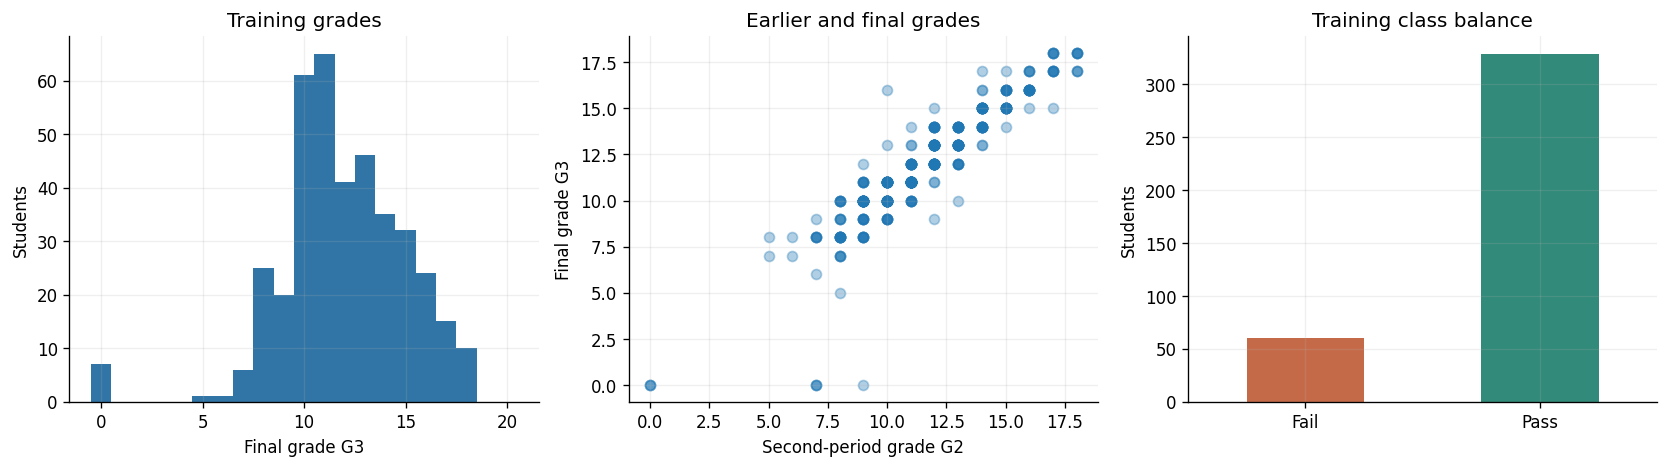

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(y_grade.loc[train_idx], bins=np.arange(-0.5, 21.5, 1), color='#3075A6')
axes[0].set(xlabel='Final grade G3', ylabel='Students', title='Training grades')
axes[1].scatter(X_train['G2'], y_grade.loc[train_idx], alpha=0.35)
axes[1].set(xlabel='Second-period grade G2', ylabel='Final grade G3', title='Earlier and final grades')
y_pass.loc[train_idx].value_counts().reindex([0, 1]).plot.bar(ax=axes[2], color=['#C56A48', '#318A7A'])
axes[2].set_xticklabels(['Fail', 'Pass'], rotation=0)
axes[2].set(ylabel='Students', title='Training class balance', xlabel='')
plt.tight_layout(); plt.show()

**Discuss:** Most students pass. Why could a model have high accuracy even if it rarely detects a failing student? Does the scatter plot establish that an earlier grade *causes* a later grade?

## 4. Simple linear regression

Use one input, `G2`, to predict `G3`:

$$\hat y = b + w x$$

`fit(X, y)` learns the coefficient and intercept. `predict(X)` applies the learned formula. In scikit-learn, `X` must be two-dimensional, so use `[['G2']]` rather than `['G2']`.

`LinearRegression` solves ordinary least squares numerically; it does **not** run the gradient-descent loop used later in this notebook.

Predicted G3 = 0.367 + 0.999 × G2
Prediction when G2 = 12: 12.35


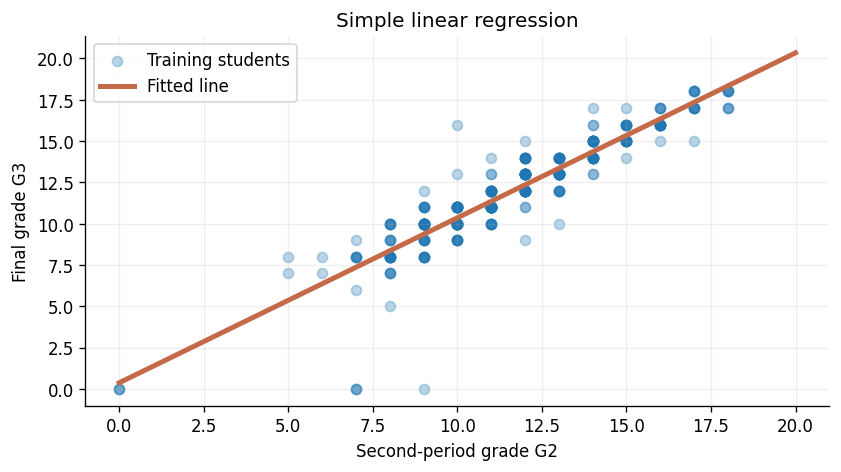

In [ ]:
simple = LinearRegression()
simple.fit(X_train[['G2']], y_grade.loc[train_idx])
print(f'Predicted G3 = {simple.intercept_:.3f} + {simple.coef_[0]:.3f} × G2')
example = pd.DataFrame({'G2': [12]})
print('Prediction when G2 = 12:', round(simple.predict(example)[0], 2))

line_x = pd.DataFrame({'G2': np.linspace(0, 20, 100)})
plt.scatter(X_train['G2'], y_grade.loc[train_idx], alpha=0.3, label='Training students')
plt.plot(line_x['G2'], simple.predict(line_x), color='#C56A48', linewidth=3, label='Fitted line')
plt.xlabel('Second-period grade G2'); plt.ylabel('Final grade G3')
plt.title('Simple linear regression'); plt.legend(); plt.show()

### Gradient descent on these real training records

For mean squared error, with residual $e_i = \hat y_i-y_i$:

$$L=\frac{1}{n}\sum_i e_i^2,\quad
\frac{\partial L}{\partial w}=\frac{2}{n}\sum_i e_i x_i,\quad
\frac{\partial L}{\partial b}=\frac{2}{n}\sum_i e_i$$

Update both parameters using their gradients from the same predictions:
$$w\leftarrow w-\eta\frac{\partial L}{\partial w},\qquad
b\leftarrow b-\eta\frac{\partial L}{\partial b}$$

We scale `G2` using **training** statistics, initialize both parameters to zero, and run full-batch gradient descent. Scaling helps keep updates well behaved. This is a transparent teaching implementation; the library model remains our main implementation.

,step,w (scaled x),b,MSE before update
0,1,0.283573,1.192031,151.663239
1,2,0.538788,2.264859,123.137570
2,3,0.768482,3.230404,100.031778


Gradient descent: G3_hat = 0.3666 + 0.9985 × G2
Least squares:    G3_hat = 0.3666 + 0.9985 × G2


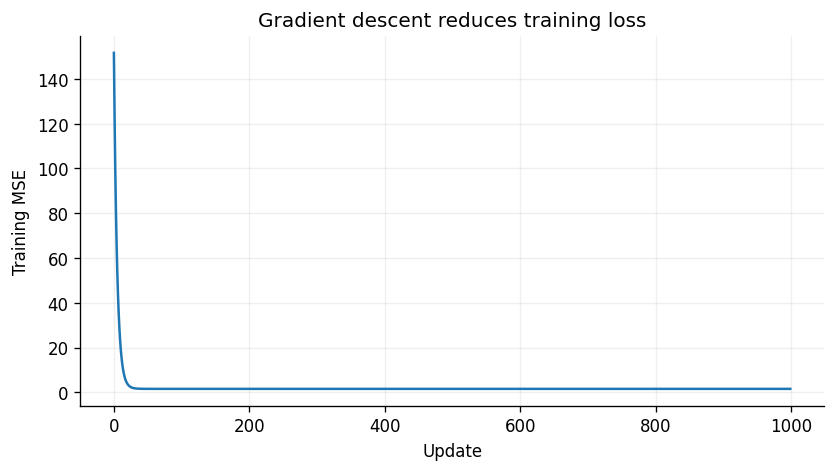

In [ ]:
gd_scaler = StandardScaler()
x_gd = gd_scaler.fit_transform(X_train[['G2']]).ravel()
target_gd = y_grade.loc[train_idx].to_numpy()
w, b, learning_rate = 0.0, 0.0, 0.05
loss_history = []
first_updates = []
for step in range(1000):
    error = b + w * x_gd - target_gd
    grad_w = 2 * np.mean(error * x_gd)
    grad_b = 2 * np.mean(error)
    loss_history.append(np.mean(error ** 2))
    w -= learning_rate * grad_w
    b -= learning_rate * grad_b
    if step < 3:
        first_updates.append({'step': step + 1, 'w (scaled x)': w, 'b': b,
                              'MSE before update': loss_history[-1]})
display(pd.DataFrame(first_updates))
# Convert the learned formula back to original grade units.
w_original = w / gd_scaler.scale_[0]
b_original = b - w * gd_scaler.mean_[0] / gd_scaler.scale_[0]
print(f'Gradient descent: G3_hat = {b_original:.4f} + {w_original:.4f} × G2')
print(f'Least squares:    G3_hat = {simple.intercept_:.4f} + {simple.coef_[0]:.4f} × G2')
plt.plot(loss_history); plt.xlabel('Update'); plt.ylabel('Training MSE')
plt.title('Gradient descent reduces training loss'); plt.show()

## 5. Multiple linear regression and safe preprocessing

Multiple regression adds several inputs to the same linear formula. Categorical variables become indicator columns through one-hot encoding. We drop one category per feature to avoid redundant dummy columns with an intercept.

A **Pipeline** keeps imputation, encoding, scaling, and fitting together. Each `.fit()` learns preprocessing statistics from the data passed to it. `.predict()` reuses those statistics.

The source data has no missing values, but we include median/mode imputation to demonstrate a reusable workflow. We scale numeric inputs for consistency with logistic regression. Scaling is not required for ordinary least-squares predictions. Coefficients for standardized numeric features represent a one-training-standard-deviation change, with other transformed inputs held fixed.

In [ ]:
def make_preprocessor():
    numeric = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    categorical = make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    return ColumnTransformer([
        ('num', numeric, numeric_features),
        ('cat', categorical, categorical_features)])

multiple = Pipeline([('prep', make_preprocessor()), ('model', LinearRegression())])
multiple.fit(X_train, y_grade.loc[train_idx])
display(pd.Series(multiple.named_steps['model'].coef_,
                  index=multiple.named_steps['prep'].get_feature_names_out(),
                  name='coefficient').to_frame())
print('Intercept:', multiple.named_steps['model'].intercept_)

,coefficient
num__G1,0.403191
num__G2,2.371504
num__failures,-0.082331
cat__studytime_2,0.366378
cat__studytime_3,0.321342
cat__studytime_4,0.249712
cat__school_MS,-0.200376
cat__internet_yes,0.178122


Intercept: 11.614070785015008


### Validation metrics and a baseline

- **MAE:** average absolute error, in grade points. Lower is better.
- **RMSE:** also in grade points; penalizes large errors more heavily. Lower is better.
- **R²:** 1 is perfect; 0 corresponds to using the evaluated sample's mean in the R² definition; negative values are possible.

The `DummyRegressor` baseline predicts the **training mean** for every student. Its validation R² need not be exactly zero because training and validation means may differ. We predeclare both linear models for the final comparison; do not repeatedly change features after looking at test results.

In [ ]:
def regression_metrics(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R2': r2_score(actual, predicted)}

reg_baseline = DummyRegressor(strategy='mean').fit(X_train, y_grade.loc[train_idx])
validation_reg = pd.DataFrame({
    'Training-mean baseline': regression_metrics(y_grade.loc[val_idx], reg_baseline.predict(X_val)),
    'Simple linear': regression_metrics(y_grade.loc[val_idx], simple.predict(X_val[['G2']])),
    'Multiple linear': regression_metrics(y_grade.loc[val_idx], multiple.predict(X_val))}).T
display(validation_reg.round(3))

,MAE,RMSE,R2
Training-mean baseline,2.377,3.315,-0.000
Simple linear,0.855,1.499,0.796
Multiple linear,0.818,1.449,0.809


## 6. Binary logistic regression: from a grade to a probability

Now change the target to `Pass = 1` and `Fail = 0`. Keep the same input features and row split.

$$z=b+\sum_j w_jx_j,\qquad p(\mathrm{Pass})=\frac{1}{1+e^{-z}}$$

At our fixed threshold of 0.50: predict Pass when $p\ge0.50$; otherwise predict Fail.

Unlike MSE for our regression example, the data-fitting loss is binary cross-entropy:
$$L=-\frac{1}{n}\sum_i[y_i\log(p_i)+(1-y_i)\log(1-p_i)].$$

Scikit-learn's logistic model also uses regularization by default. Here `solver='lbfgs'` uses a numerical optimizer, rather than a plain gradient-descent loop. `C` is inverse regularization strength: smaller `C` means stronger regularization. `max_iter` is a solver iteration limit, not a neural-network epoch count.

First use only `G2` to see the sigmoid clearly. Then fit the richer feature set.

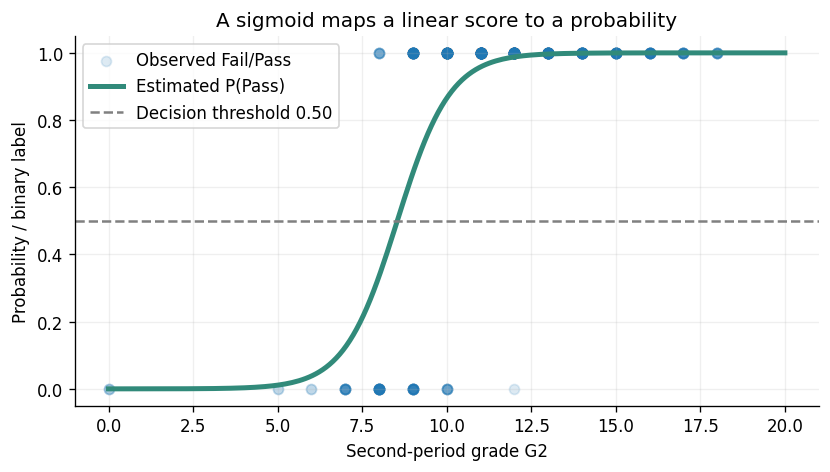

For G2=14: z=6.942, sigmoid(z)=0.999
Library probability: 0.9990347231871285


In [ ]:
single_logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, solver='lbfgs'))
single_logistic.fit(X_train[['G2']], y_pass.loc[train_idx])
grid = pd.DataFrame({'G2': np.linspace(0, 20, 200)})
positive_col = np.flatnonzero(single_logistic.classes_ == 1)[0]
prob_curve = single_logistic.predict_proba(grid)[:, positive_col]
plt.scatter(X_train['G2'], y_pass.loc[train_idx], alpha=0.15, label='Observed Fail/Pass')
plt.plot(grid['G2'], prob_curve, color='#318A7A', linewidth=3, label='Estimated P(Pass)')
plt.axhline(0.5, linestyle='--', color='gray', label='Decision threshold 0.50')
plt.xlabel('Second-period grade G2'); plt.ylabel('Probability / binary label')
plt.title('A sigmoid maps a linear score to a probability'); plt.legend(); plt.show()

row = X_train[['G2']].iloc[[0]]
z = single_logistic.decision_function(row)[0]
p_manual = 1 / (1 + np.exp(-z))
print(f'For G2={row.iloc[0, 0]}: z={z:.3f}, sigmoid(z)={p_manual:.3f}')
print('Library probability:', single_logistic.predict_proba(row)[0, positive_col])

## 7. Select a logistic model using validation data

Try only three predeclared values of `C`: 0.1, 1, and 10. Select the value with the highest validation **macro F1** at threshold 0.50. Break ties by choosing the smaller `C`.

Macro F1 averages the F1 scores for Fail and Pass equally. Positive-class precision and recall below refer to **Pass**. Detecting students who fail is a different objective, so the classification report later shows recall for both classes.

A **most-frequent-class baseline** helps expose misleading accuracy. `predict_proba()` returns columns in the order of `classes_`; always check that order.

In [ ]:
def pass_probability(model, X_part):
    col = np.flatnonzero(model.classes_ == 1)[0]
    return model.predict_proba(X_part)[:, col]

def classification_metrics(actual, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    return {'accuracy': accuracy_score(actual, prediction),
            'balanced_accuracy': balanced_accuracy_score(actual, prediction),
            'precision_Pass': precision_score(actual, prediction, zero_division=0),
            'recall_Pass': recall_score(actual, prediction, zero_division=0),
            'macro_F1': f1_score(actual, prediction, average='macro', zero_division=0),
            'log_loss': log_loss(actual, np.column_stack([1-probability, probability]), labels=[0, 1]),
            'ROC_AUC': roc_auc_score(actual, probability)}

candidates, records = {}, []
for C in [0.1, 1.0, 10.0]:
    candidate = Pipeline([('prep', make_preprocessor()),
                          ('model', LogisticRegression(C=C, max_iter=2000, solver='lbfgs'))])
    candidate.fit(X_train, y_pass.loc[train_idx])
    candidates[C] = candidate
    records.append({'C': C, **classification_metrics(y_pass.loc[val_idx], pass_probability(candidate, X_val))})
validation_clf = pd.DataFrame(records).sort_values(['macro_F1', 'C'], ascending=[False, True])
best_C = float(validation_clf.iloc[0]['C'])
best_logistic = candidates[best_C]
display(validation_clf.round(3))
print('Selected C:', best_C)

class_baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_pass.loc[train_idx])
print('Baseline validation accuracy:', round(class_baseline.score(X_val, y_pass.loc[val_idx]), 3))
print('Baseline validation macro F1:', round(f1_score(y_pass.loc[val_idx], class_baseline.predict(X_val), average='macro'), 3))

,C,accuracy,balanced_accuracy,precision_Pass,recall_Pass,macro_F1,log_loss,ROC_AUC
1,1.0,0.962,0.916,0.973,0.982,0.925,0.140,0.979
0,0.1,0.954,0.891,0.964,0.982,0.908,0.150,0.982
2,10.0,0.954,0.891,0.964,0.982,0.908,0.145,0.980


Selected C: 1.0
Baseline validation accuracy: 0.846
Baseline validation macro F1: 0.458


### Thresholds change the decision, not the fitted probabilities

Compare thresholds on **validation** data. Lowering the Pass threshold usually predicts more students as Pass, increasing Pass recall while potentially missing more failing students. A support-screening system might instead define Fail as the positive class.

Here we keep 0.50 fixed for the final test. In a real application, choose a threshold on validation data according to the costs of the two error types, then freeze it before testing. Do not choose a threshold using test results.

In [ ]:
val_probability = pass_probability(best_logistic, X_val)
display(pd.DataFrame([
    {'threshold': t, **classification_metrics(y_pass.loc[val_idx], val_probability, t)}
    for t in [0.3, 0.5, 0.7]
])[['threshold', 'precision_Pass', 'recall_Pass', 'macro_F1', 'accuracy']].round(3))

,threshold,precision_Pass,recall_Pass,macro_F1,accuracy
0,0.3,0.956,0.982,0.890,0.946
1,0.5,0.973,0.982,0.925,0.962
2,0.7,0.972,0.955,0.886,0.938


## 8. Final evaluation after freezing choices

We now refit the predeclared linear models, baselines, and selected logistic configuration on **training + validation** data. Pipelines correctly refit their preprocessing on that combined development set. We use the test set for final reporting only.

No tuning follows these results. If the test reveals a weakness, report it. Further development needs a fresh untouched holdout or an appropriately nested evaluation.

In [ ]:
X_development, X_test = X.loc[trainval_idx], X.loc[test_idx]
final_simple = clone(simple).fit(X_development[['G2']], y_grade.loc[trainval_idx])
final_multiple = clone(multiple).fit(X_development, y_grade.loc[trainval_idx])
final_reg_baseline = DummyRegressor(strategy='mean').fit(X_development, y_grade.loc[trainval_idx])
final_logistic = clone(best_logistic).fit(X_development, y_pass.loc[trainval_idx])
final_class_baseline = DummyClassifier(strategy='most_frequent').fit(X_development, y_pass.loc[trainval_idx])

simple_test_pred = final_simple.predict(X_test[['G2']])
multiple_test_pred = final_multiple.predict(X_test)
test_probability = pass_probability(final_logistic, X_test)
test_prediction = (test_probability >= 0.5).astype(int)

display(pd.DataFrame({
    'Mean baseline': regression_metrics(y_grade.loc[test_idx], final_reg_baseline.predict(X_test)),
    'Simple linear': regression_metrics(y_grade.loc[test_idx], simple_test_pred),
    'Multiple linear': regression_metrics(y_grade.loc[test_idx], multiple_test_pred)}).T.round(3))
display(pd.DataFrame([classification_metrics(y_pass.loc[test_idx], test_probability)], index=['Logistic: final test']).round(3))
print('Most-frequent baseline test accuracy:', round(final_class_baseline.score(X_test, y_pass.loc[test_idx]), 3))
print('Most-frequent baseline test macro F1:', round(f1_score(y_pass.loc[test_idx], final_class_baseline.predict(X_test), average='macro'), 3))

,MAE,RMSE,R2
Mean baseline,2.564,3.522,-0.001
Simple linear,0.732,1.150,0.893
Multiple linear,0.751,1.202,0.883


,accuracy,balanced_accuracy,precision_Pass,recall_Pass,macro_F1,log_loss,ROC_AUC
Logistic: final test,0.931,0.816,0.939,0.982,0.851,0.139,0.981


Most-frequent baseline test accuracy: 0.846
Most-frequent baseline test macro F1: 0.458


### Error analysis

The actual-versus-predicted plot should follow the diagonal. Residuals are `actual − predicted`; systematic patterns suggest model limitations. Linear regression can predict outside 0–20 because its output is unbounded. We report raw predictions without clipping or rounding.

The confusion matrix uses **rows = actual**, **columns = predicted**, with Pass as positive:

| | Predicted Fail | Predicted Pass |
|---|---|---|
| Actual Fail | True negative | False positive |
| Actual Pass | False negative | True positive |

A false positive here means a student who fails was predicted to pass.

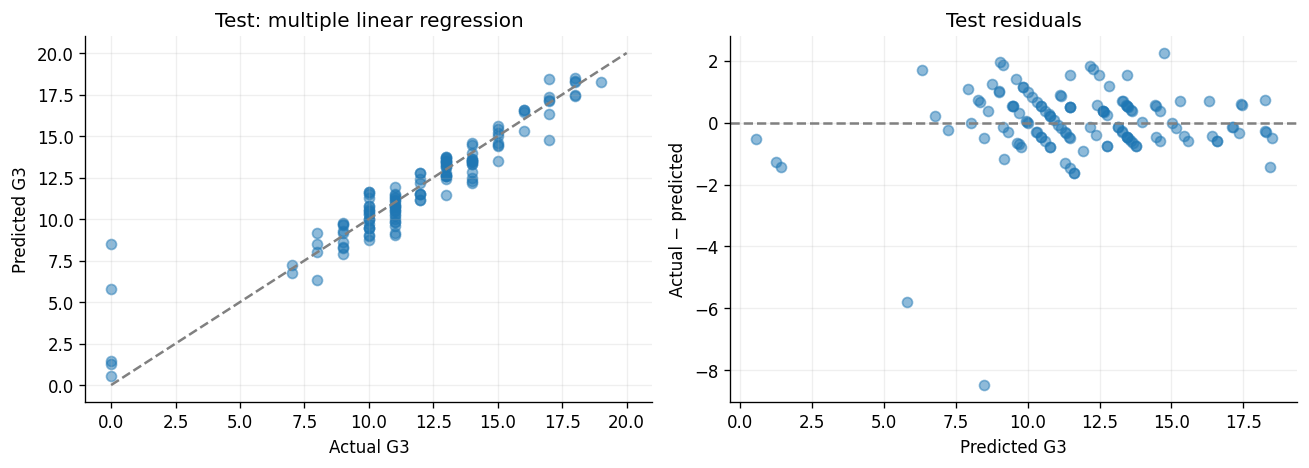

Predictions outside 0–20: 0


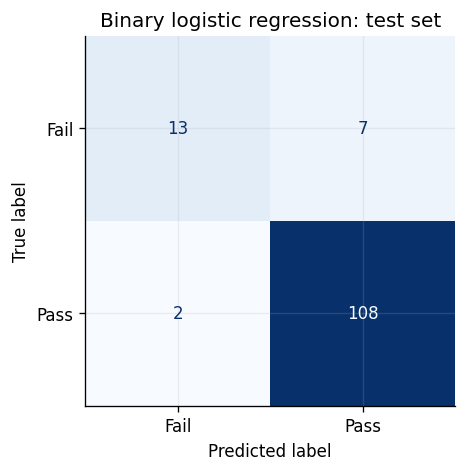

              precision    recall  f1-score   support

        Fail       0.87      0.65      0.74        20
        Pass       0.94      0.98      0.96       110

    accuracy                           0.93       130
   macro avg       0.90      0.82      0.85       130
weighted avg       0.93      0.93      0.93       130



In [ ]:
actual_grade = y_grade.loc[test_idx].to_numpy()
residuals = actual_grade - multiple_test_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(actual_grade, multiple_test_pred, alpha=0.5)
limits = [min(0, multiple_test_pred.min()), max(20, multiple_test_pred.max())]
axes[0].plot(limits, limits, '--', color='gray')
axes[0].set(xlabel='Actual G3', ylabel='Predicted G3', title='Test: multiple linear regression')
axes[1].scatter(multiple_test_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set(xlabel='Predicted G3', ylabel='Actual − predicted', title='Test residuals')
plt.tight_layout(); plt.show()
print('Predictions outside 0–20:', int(((multiple_test_pred < 0) | (multiple_test_pred > 20)).sum()))
ConfusionMatrixDisplay.from_predictions(y_pass.loc[test_idx], test_prediction,
    labels=[0, 1], display_labels=['Fail', 'Pass'], cmap='Blues', colorbar=False)
plt.title('Binary logistic regression: test set'); plt.show()
print(classification_report(y_pass.loc[test_idx], test_prediction,
                            labels=[0, 1], target_names=['Fail', 'Pass'], zero_division=0))

## 9. Make predictions for the same students

Each row below has two different outputs: a predicted numeric grade and an estimated probability of passing. The probability is not a predicted grade. The independently fitted models can disagree.

**Check your understanding:** For a probability of 0.48, what class do we predict at thresholds 0.50 and 0.40? Which threshold would make a Pass prediction easier?

In [ ]:
comparison = X_test.head(8).copy()
comparison['actual_grade'] = y_grade.loc[comparison.index]
comparison['predicted_grade'] = multiple_test_pred[:8]
comparison['P(Pass)'] = test_probability[:8]
comparison['predicted_class'] = np.where(test_prediction[:8] == 1, 'Pass', 'Fail')
display(comparison.round(2))

,G1,G2,failures,studytime,school,internet,actual_grade,predicted_grade,P(Pass),predicted_class
313,13,13,0,2,GP,no,13,13.45,1.00,Pass
185,16,17,0,2,GP,yes,18,17.44,1.00,Pass
292,11,12,0,3,GP,yes,14,12.47,0.99,Pass
501,14,12,0,1,MS,yes,13,12.42,1.00,Pass
68,11,10,0,2,GP,yes,11,10.78,0.97,Pass
600,12,13,0,1,MS,no,14,12.81,1.00,Pass
615,15,14,0,2,MS,no,15,14.42,1.00,Pass
502,10,8,1,4,MS,no,9,8.26,0.54,Pass
